# Image feature extraction -- MobileNetV2 fine-tuned on Zenodo (Category classification)

One of **4 separate notebooks** comparing lightweight backbones for the
"Image Feature Extraction" block in your fusion diagram -- this one is
**MobileNetV2**. The other three (MobileNetV3-Small, EfficientNetB0, EfficientNetV2B0) are separate notebooks with
the identical pipeline, so results are comparable apples-to-apples. Kept
separate (not one big multi-model kernel) for the same memory/restart
reasons as the earlier segmentation ablation work.

**What this does:**
1. Loads the patient-level train/val/test split (folder-per-class under
   each split -- see prerequisite below).
2. Fine-tunes MobileNetV2 (ImageNet-pretrained) in two phases: frozen backbone
   first, then unfrozen fine-tuning at a low LR -- same recipe used
   successfully in the segmentation notebooks.
3. Reports accuracy / macro-F1 / per-class metrics / confusion matrix on
   val and test, and **appends one row to a shared comparison CSV** so all
   4 backbone notebooks' results land in the same table.
4. **Extracts and saves the penultimate-layer feature vector** for every
   image (train/val/test) -- this is the actual deliverable for the fusion
   stage: a `.npz` of embeddings + a CSV mapping each row back to its image
   name, patient ID, category, and split.

Classic lightweight backbone (~3.5M params), no built-in preprocessing -- needs keras.applications.mobilenet_v2.preprocess_input (scales to [-1, 1]).

### Prerequisite
Run the patient-level split notebook first, with its `SOURCE_IMAGES_DIR`
pointed at your **`segmented_oral_cavity_cropped`** folder (not the original
images) -- that gives you `<split_root>/train/<Category>/*.png`,
`<split_root>/val/<Category>/*.png`, `<split_root>/test/<Category>/*.png`,
which is what Section 1 below asks for.

**Nothing in your split folder is ever moved, renamed, or deleted** -- this
notebook only reads images and writes to its own output folder.


In [1]:
# ============================================================
# 1. CONFIG -- EDIT THESE PATHS FOR YOUR KAGGLE NOTEBOOK
# ============================================================
from pathlib import Path

# --- INPUT: this is the STAGE-A SCREENING run (all 4 backbones, same data, to pick a
# winner) -- point it at the AUGMENTED split (train/val/test subfolders, produced by your
# augmentation notebook: OCA oversampled in train only, val/test unchanged, patient-level
# split preserved) as a Kaggle Dataset. Upload that `augmented_dataset` folder as a Kaggle
# Dataset, attach it to this notebook as an input, then point this at it. Kaggle mounts
# dataset inputs read-only under /kaggle/input/<dataset-name>/ -- adjust <your-dataset-name>
# below to whatever you named it when you uploaded it.
# (If you'd rather screen on the plain, non-augmented split instead, point this at that
# split-root folder -- the folder shape is identical, train/val/test/<Category>/.)
SPLIT_ROOT = Path("/kaggle/input/datasets/gokulkrishnabr/augmented-zenodo/augmented_dataset")
for _s in ("train", "val", "test"):
    assert (SPLIT_ROOT / _s).is_dir(), f"{SPLIT_ROOT / _s} not found -- fix SPLIT_ROOT above."

# --- OUTPUT: /kaggle/working is this notebook's own writable scratch space (20GB quota).
# Everything this notebook produces -- weights, curves, embeddings, the comparison CSV --
# gets saved here. After the run finishes, use Kaggle's "Save Version" (or the Output tab)
# to keep these files -- /kaggle/working is wiped when the session ends otherwise.
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- COMPARISON CSV: each of the 4 backbone notebooks runs in its OWN isolated Kaggle
# session, so there is no live shared file between them. This just writes THIS backbone's
# one row locally to /kaggle/working. After all 4 notebooks have run, download each one's
# CSV from its Output tab and combine them yourself (a couple of lines of pandas.concat,
# or re-upload the earlier CSVs as a small Kaggle Dataset input to a final notebook that
# combines them) -- Section 6 below still knows how to append if you DO make a previous
# run's CSV available as an input here.
COMPARISON_CSV = OUTPUT_DIR / "image_model_comparison.csv"

BACKBONE_NAME = "MobileNetV2"
IMG_SIZE = 224          # fixed across all 4 backbone notebooks for a fair comparison
BATCH_SIZE = 32
PHASE1_EPOCHS = 15      # frozen backbone, head only
PHASE2_EPOCHS = 25      # fine-tune, unfrozen backbone at low LR (per LR variant below)
PHASE1_LR = 1e-3
# Phase-2 fine-tuning LR sweep: each of these is tried in turn, starting fresh from the
# phase-1 checkpoint every time, and the one with the best val_accuracy wins. 1e-5 is the
# "safe" choice used before; the other two let fine-tuning move faster if the backbone
# tolerates it. Edit this list to add/remove LR candidates.
PHASE2_LRS = [1e-5, 5e-5, 1e-4]
EARLY_STOP_PATIENCE = 8
RANDOM_SEED = 42

print()
print("Split root      :", SPLIT_ROOT)
print("Output folder    :", OUTPUT_DIR)
print("Comparison CSV (this run's row) :", COMPARISON_CSV)
print("Backbone          :", BACKBONE_NAME)



Split root      : /kaggle/input/datasets/gokulkrishnabr/augmented-zenodo/augmented_dataset
Output folder    : /kaggle/working
Comparison CSV (this run's row) : /kaggle/working/image_model_comparison.csv
Backbone          : MobileNetV2


In [2]:
# ============================================================
# 2. IMPORTS + tf.data PIPELINES
# ============================================================
import time
import json as _json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras.applications import MobileNetV2
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__, " Keras:", keras.__version__)
tf.random.set_seed(RANDOM_SEED)

train_ds_raw = keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "train", image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=True, seed=RANDOM_SEED)
val_ds_raw = keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "val", image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)
test_ds_raw = keras.utils.image_dataset_from_directory(
    SPLIT_ROOT / "test", image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
    label_mode="categorical", shuffle=False)

CLASS_NAMES = train_ds_raw.class_names
N_CLASSES = len(CLASS_NAMES)
print("Classes:", CLASS_NAMES)
assert val_ds_raw.class_names == CLASS_NAMES and test_ds_raw.class_names == CLASS_NAMES, (
    "Class folder names differ between train/val/test -- check the split notebook's output.")

from keras.applications.mobilenet_v2 import preprocess_input
def preprocess(x, y):
    return preprocess_input(x), y

train_ds = train_ds_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
test_ds = test_ds_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)

# class weights (from TRAIN split only) -- OCA is much rarer than the other classes
train_labels_flat = []
for _, y in train_ds_raw.unbatch():
    train_labels_flat.append(int(tf.argmax(y).numpy()))
train_labels_flat = np.array(train_labels_flat)
class_weight_arr = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=train_labels_flat)
CLASS_WEIGHT = {i: w for i, w in enumerate(class_weight_arr)}
print("Class weights (train, balanced):", {CLASS_NAMES[i]: round(w, 3) for i, w in CLASS_WEIGHT.items()})


TensorFlow: 2.20.0  Keras: 3.13.2
Found 2237 files belonging to 4 classes.


I0000 00:00:1790352537.011870      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790352537.015088      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 517 files belonging to 4 classes.
Found 550 files belonging to 4 classes.
Classes: ['Benign', 'Healthy', 'OCA', 'OPMD']
Class weights (train, balanced): {'Benign': np.float64(1.137), 'Healthy': np.float64(1.163), 'OCA': np.float64(1.472), 'OPMD': np.float64(0.633)}


In [3]:
# ============================================================
# 3. BUILD THE MODEL -- MobileNetV2 backbone + classification head
# ============================================================
base_model = MobileNetV2(
    include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
base_model.trainable = False   # phase 1: frozen

inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
features = base_model(inputs, training=False)   # this IS the feature vector used later for fusion
x = keras.layers.Dropout(0.3, name="head_dropout")(features)
outputs = keras.layers.Dense(N_CLASSES, activation="softmax", name="head_dense")(x)
model = keras.Model(inputs, outputs, name=f"{BACKBONE_NAME}_category_classifier")

total_params = model.count_params()
trainable_phase1 = sum(int(np.prod(v.shape)) for v in model.trainable_weights)
fp32_mb = total_params * 4 / (1024 ** 2)
print(f"SIZE  : {total_params:,} total params, {trainable_phase1:,} trainable in phase 1, "
      f"{fp32_mb:.2f} MB FP32")
print("Feature vector dimensionality (for fusion):", base_model.output_shape[-1])

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
SIZE  : 2,263,108 total params, 5,124 trainable in phase 1, 8.63 MB FP32
Feature vector dimensionality (for fusion): 1280


Model: "MobileNetV2_category_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dense (Dense)              │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15


2026-09-25 16:11:19.666415: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:11:19.808396: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1790352682.688492      75 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


69/70 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.2937 - loss: 1.6805

2026-09-25 16:12:53.666534: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:12:53.801805: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:12:53.941484: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:12:54.076695: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2945 - loss: 1.6779

2026-09-25 16:13:31.489843: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:13:31.643423: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 16:13:31.779843: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


70/70 ━━━━━━━━━━━━━━━━━━━━ 159s 2s/step - accuracy: 0.3482 - loss: 1.4955 - val_accuracy: 0.4371 - val_loss: 1.2448
Epoch 2/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 122s 2s/step - accuracy: 0.4551 - loss: 1.2057 - val_accuracy: 0.4971 - val_loss: 1.1456
Epoch 3/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.5114 - loss: 1.0727 - val_accuracy: 0.5145 - val_loss: 1.1047
Epoch 4/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.5396 - loss: 1.0042 - val_accuracy: 0.5068 - val_loss: 1.1260
Epoch 5/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 121s 2s/step - accuracy: 0.5610 - loss: 0.9748 - val_accuracy: 0.5068 - val_loss: 1.0963
Epoch 6/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.5762 - loss: 0.9410 - val_accuracy: 0.5087 - val_loss: 1.0886
Epoch 7/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 120s 2s/step - accuracy: 0.5995 - loss: 0.9064 - val_accuracy: 0.5106 - val_loss: 1.1435
Epoch 8/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 120s 2s/step - accuracy: 0.5995 - loss: 0.8780 - val_accuracy: 0.5300 - val_loss: 1.

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 318 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


70/70 ━━━━━━━━━━━━━━━━━━━━ 183s 2s/step - accuracy: 0.5110 - loss: 1.1997 - val_accuracy: 0.5416 - val_loss: 1.1078
Epoch 2/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.7000 - loss: 0.6603 - val_accuracy: 0.5397 - val_loss: 1.1446
Epoch 3/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8033 - loss: 0.4395 - val_accuracy: 0.5416 - val_loss: 1.1478
Epoch 4/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.8869 - loss: 0.2913 - val_accuracy: 0.5435 - val_loss: 1.1738
Epoch 5/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 141s 2s/step - accuracy: 0.9365 - loss: 0.2067 - val_accuracy: 0.5455 - val_loss: 1.2222
Epoch 6/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.9616 - loss: 0.1375 - val_accuracy: 0.5474 - val_loss: 1.2825
Epoch 7/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 119s 2s/step - accuracy: 0.9794 - loss: 0.1010 - val_accuracy: 0.5706 - val_loss: 1.3126
Epoch 8/25
70/70 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.9844 - loss: 0.0713 - val_accuracy: 0.5687 - val_loss: 1.

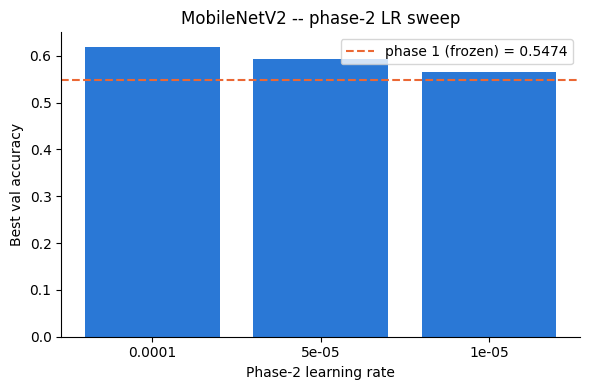

\nTotal training time (phase 1 + full LR sweep): 137.8 min
Winning checkpoint: phase2 (fine-tuned, LR=0.0001)


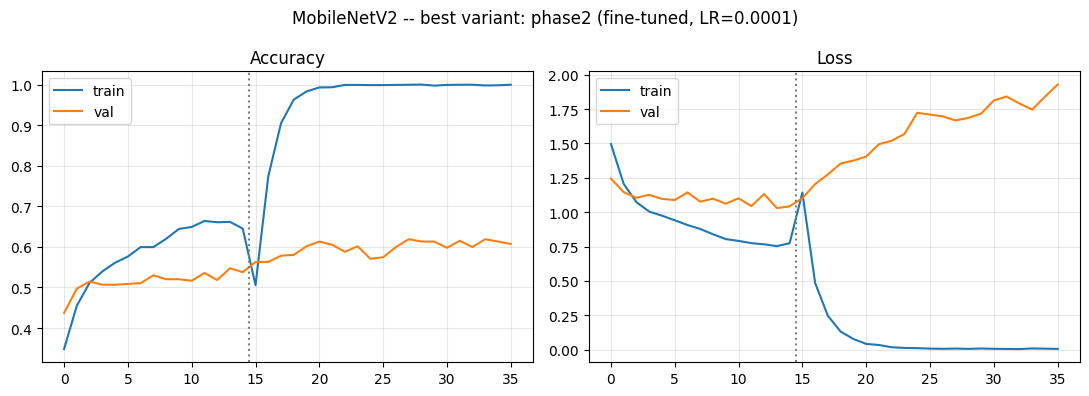

In [4]:
# ============================================================
# 4. TWO-PHASE TRAINING, WITH A PHASE-2 LEARNING-RATE SWEEP
#    Phase 1 (frozen backbone) runs once. Phase 2 (fine-tune) is then tried
#    once per LR in PHASE2_LRS, each time starting FRESH from the phase-1
#    checkpoint (so the sweep is fair -- no variant gets a head start from
#    a previous variant's fine-tuning). Whichever checkpoint -- phase 1, or
#    one of the phase-2 LR variants -- has the best val_accuracy wins and is
#    what Sections 5-7 evaluate/save. Separate checkpoint files avoid the
#    ModelCheckpoint "best" reset bug where a new run overwrites an earlier,
#    better checkpoint on its first epoch.
# ============================================================
PHASE1_WEIGHTS = OUTPUT_DIR / f"{BACKBONE_NAME}_phase1.weights.h5"
HISTORY_CSV = OUTPUT_DIR / f"{BACKBONE_NAME}_history.csv"
LR_SWEEP_CSV = OUTPUT_DIR / f"{BACKBONE_NAME}_phase2_lr_sweep.csv"

t0 = time.time()

# --- Phase 1: frozen backbone, train the head only ---
model.compile(optimizer=keras.optimizers.Adam(PHASE1_LR),
              loss="categorical_crossentropy", metrics=["accuracy"])
cb1 = [
    keras.callbacks.ModelCheckpoint(str(PHASE1_WEIGHTS), save_best_only=True,
                                     save_weights_only=True, monitor="val_accuracy", mode="max"),
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                   patience=EARLY_STOP_PATIENCE, restore_best_weights=True),
]
hist1 = model.fit(train_ds, validation_data=val_ds, epochs=PHASE1_EPOCHS,
                   class_weight=CLASS_WEIGHT, callbacks=cb1, verbose=1)
phase1_epochs_run = len(hist1.history["loss"])
model.load_weights(str(PHASE1_WEIGHTS))
phase1_val_acc = max(hist1.history["val_accuracy"])
print(f"\\nPhase 1 done: {phase1_epochs_run} epochs, best val_accuracy = {phase1_val_acc:.4f}")

# --- Phase 2: unfreeze, sweep fine-tuning learning rates ---
base_model.trainable = True
trainable_phase2 = sum(int(np.prod(v.shape)) for v in model.trainable_weights)

sweep_results = []
phase2_histories = {}
for lr in PHASE2_LRS:
    print(f"\\n--- Phase 2 variant: PHASE2_LR = {lr:g} (starting fresh from phase-1 weights) ---")
    model.load_weights(str(PHASE1_WEIGHTS))   # reset to phase-1 state so each LR gets a fair, independent shot
    variant_weights = OUTPUT_DIR / f"{BACKBONE_NAME}_phase2_lr{lr:g}.weights.h5"
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    cb2 = [
        keras.callbacks.ModelCheckpoint(str(variant_weights), save_best_only=True,
                                         save_weights_only=True, monitor="val_accuracy", mode="max"),
        keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max",
                                       patience=EARLY_STOP_PATIENCE, restore_best_weights=True),
    ]
    hist_variant = model.fit(train_ds, validation_data=val_ds, epochs=PHASE2_EPOCHS,
                              class_weight=CLASS_WEIGHT, callbacks=cb2, verbose=1)
    variant_epochs_run = len(hist_variant.history["loss"])
    variant_val_acc = max(hist_variant.history["val_accuracy"]) if hist_variant.history["val_accuracy"] else -1
    print(f"LR {lr:g} done: {variant_epochs_run} epochs, best val_accuracy = {variant_val_acc:.4f}")
    sweep_results.append({
        "phase2_lr": lr, "epochs_run": variant_epochs_run, "val_accuracy": round(variant_val_acc, 4),
        "weights_path": str(variant_weights),
    })
    phase2_histories[lr] = hist_variant

sweep_df = pd.DataFrame(sweep_results).sort_values("val_accuracy", ascending=False).reset_index(drop=True)
sweep_df.to_csv(LR_SWEEP_CSV, index=False)
print("\\nPhase-2 LR sweep results (best first):")
print(sweep_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([f"{lr:g}" for lr in sweep_df["phase2_lr"]], sweep_df["val_accuracy"], color="#2a78d6")
ax.axhline(phase1_val_acc, ls="--", c="#eb6834", label=f"phase 1 (frozen) = {phase1_val_acc:.4f}")
ax.set_xlabel("Phase-2 learning rate"); ax.set_ylabel("Best val accuracy")
ax.set_title(f"{BACKBONE_NAME} -- phase-2 LR sweep")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{BACKBONE_NAME}_lr_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

best_variant_lr = sweep_df.iloc[0]["phase2_lr"]
best_variant_val_acc = sweep_df.iloc[0]["val_accuracy"]
best_variant_epochs = int(sweep_df.iloc[0]["epochs_run"])
best_variant_weights = sweep_df.iloc[0]["weights_path"]

training_minutes = (time.time() - t0) / 60
print(f"\\nTotal training time (phase 1 + full LR sweep): {training_minutes:.1f} min")

# pick the overall winner explicitly -- don't assume fine-tuning (at any LR) always helps
if best_variant_val_acc >= phase1_val_acc:
    model.load_weights(best_variant_weights)
    winning_phase = f"phase2 (fine-tuned, LR={best_variant_lr:g})"
    phase2_epochs_run = best_variant_epochs
    winning_phase2_lr = best_variant_lr
else:
    model.load_weights(str(PHASE1_WEIGHTS))
    winning_phase = "phase1 (frozen backbone)"
    phase2_epochs_run = 0
    winning_phase2_lr = None
print("Winning checkpoint:", winning_phase)

# plot the winning phase-2 variant's curves against phase 1 (not every variant, to keep this readable)
best_hist2 = phase2_histories[best_variant_lr]
history_df = pd.concat([
    pd.DataFrame(hist1.history).assign(phase=1),
    pd.DataFrame(best_hist2.history).assign(phase=2),
], ignore_index=True)
history_df.to_csv(HISTORY_CSV, index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["accuracy"], label="train"); axes[0].plot(history_df["val_accuracy"], label="val")
axes[0].axvline(phase1_epochs_run - 0.5, ls=":", c="gray")
axes[0].set_title("Accuracy"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(history_df["loss"], label="train"); axes[1].plot(history_df["val_loss"], label="val")
axes[1].axvline(phase1_epochs_run - 0.5, ls=":", c="gray")
axes[1].set_title("Loss"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.suptitle(f"{BACKBONE_NAME} -- best variant: {winning_phase}")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / f"{BACKBONE_NAME}_curves.png", dpi=150, bbox_inches="tight")
plt.show()


\n=== val ===
Accuracy: 0.6190   Macro F1: 0.4618
              precision    recall  f1-score   support

      Benign       0.51      0.63      0.56       128
     Healthy       0.62      0.59      0.60       123
         OCA       0.00      0.00      0.00        16
        OPMD       0.69      0.67      0.68       250

    accuracy                           0.62       517
   macro avg       0.46      0.47      0.46       517
weighted avg       0.61      0.62      0.61       517



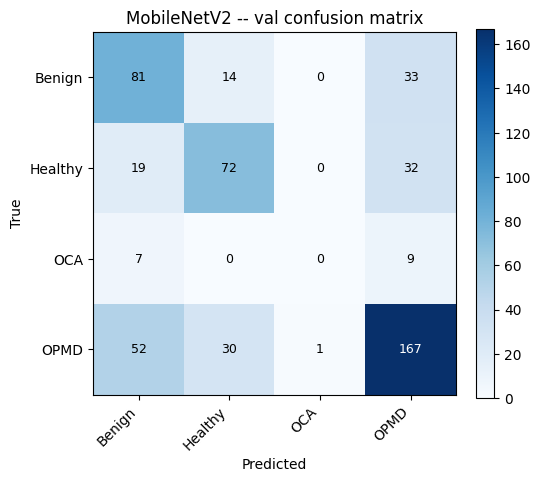

2026-09-25 18:29:48.588450: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:29:48.740190: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-25 18:29:48.876740: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


\n=== test ===
Accuracy: 0.5564   Macro F1: 0.4438
              precision    recall  f1-score   support

      Benign       0.41      0.59      0.49       128
     Healthy       0.57      0.53      0.55       125
         OCA       1.00      0.05      0.10        37
        OPMD       0.65      0.62      0.64       260

    accuracy                           0.56       550
   macro avg       0.66      0.45      0.44       550
weighted avg       0.60      0.56      0.55       550



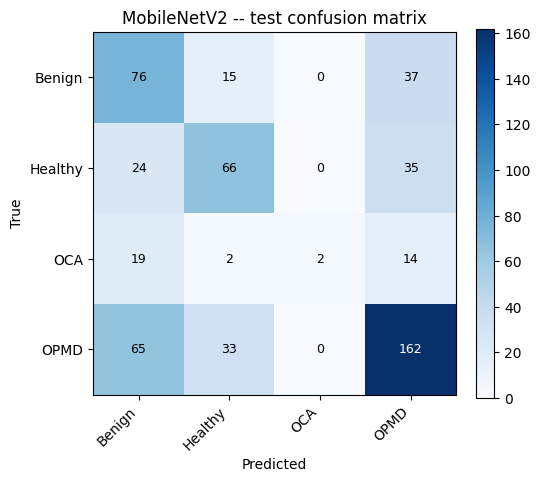

In [5]:
# ============================================================
# 5. EVALUATE ON VAL + TEST
# ============================================================
def evaluate_split(ds, ds_name):
    y_true, y_pred = [], []
    for xb, yb in ds:
        preds = model.predict(xb, verbose=0)
        y_true.extend(np.argmax(yb.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))
    y_true, y_pred = np.array(y_true), np.array(y_pred)

    acc = float((y_true == y_pred).mean())
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    report = classification_report(y_true, y_pred, target_names=CLASS_NAMES, output_dict=True)
    print(f"\\n=== {ds_name} ===")
    print(f"Accuracy: {acc:.4f}   Macro F1: {macro_f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(f"{BACKBONE_NAME} -- {ds_name} confusion matrix")
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
    plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{BACKBONE_NAME}_{ds_name.lower()}_confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()
    return acc, macro_f1, report


val_acc, val_macro_f1, val_report = evaluate_split(val_ds, "val")
test_acc, test_macro_f1, test_report = evaluate_split(test_ds, "test")

with open(OUTPUT_DIR / f"{BACKBONE_NAME}_classification_reports.json", "w") as f:
    _json.dump({"val": val_report, "test": test_report}, f, indent=2)


In [6]:
# ============================================================
# 6. APPEND TO THE SHARED COMPARISON CSV (all 4 backbone notebooks write here)
# ============================================================
comparison_row = {
    "backbone": BACKBONE_NAME,
    "img_size": IMG_SIZE,
    "total_params": total_params,
    "trainable_params_phase1": trainable_phase1,
    "trainable_params_phase2": trainable_phase2,
    "fp32_mb": round(fp32_mb, 2),
    "feature_dim": base_model.output_shape[-1],
    "phase1_epochs_run": phase1_epochs_run,
    "phase2_epochs_run": phase2_epochs_run,
    "phase2_lrs_tried": ",".join(f"{lr:g}" for lr in PHASE2_LRS),
    "winning_phase": winning_phase,
    "winning_phase2_lr": winning_phase2_lr,
    "training_minutes": round(training_minutes, 2),
    "val_accuracy": round(val_acc, 4),
    "val_macro_f1": round(val_macro_f1, 4),
    "test_accuracy": round(test_acc, 4),
    "test_macro_f1": round(test_macro_f1, 4),
}

if COMPARISON_CSV.exists():
    cmp_df = pd.read_csv(COMPARISON_CSV)
    cmp_df = cmp_df[cmp_df["backbone"] != BACKBONE_NAME]   # replace a prior run of this same backbone
    cmp_df = pd.concat([cmp_df, pd.DataFrame([comparison_row])], ignore_index=True)
else:
    cmp_df = pd.DataFrame([comparison_row])
cmp_df.to_csv(COMPARISON_CSV, index=False)

print("Appended this run to:", COMPARISON_CSV)
print(cmp_df.to_string(index=False))
print()
print("Once all 4 backbone notebooks have run, re-open this CSV (or re-run this cell in any of")
print("them) to see the full comparison table across MobileNetV2 / MobileNetV3-Small /")
print("EfficientNetB0 / EfficientNetV2B0.")


Appended this run to: /kaggle/working/image_model_comparison.csv
   backbone  img_size  total_params  trainable_params_phase1  trainable_params_phase2  fp32_mb  feature_dim  phase1_epochs_run  phase2_epochs_run   phase2_lrs_tried                  winning_phase  winning_phase2_lr  training_minutes  val_accuracy  val_macro_f1  test_accuracy  test_macro_f1
MobileNetV2       224       2263108                     5124                  2228996     8.63         1280                 15                 21 1e-05,5e-05,0.0001 phase2 (fine-tuned, LR=0.0001)             0.0001            137.79         0.619        0.4618         0.5564         0.4438

Once all 4 backbone notebooks have run, re-open this CSV (or re-run this cell in any of
them) to see the full comparison table across MobileNetV2 / MobileNetV3-Small /
EfficientNetB0 / EfficientNetV2B0.


In [7]:
# ============================================================
# 7. EXTRACT + SAVE FEATURE EMBEDDINGS -- the actual deliverable for fusion
#    One row per image: the penultimate-layer (MobileNetV2's pooled output,
#    NOT the final softmax) -- this is what gets concatenated with the
#    metadata vector in the fusion notebook.
# ============================================================
# NOTE: `features` (not base_model.output) -- base_model.output refers to the backbone's
# OWN internal graph from its own Input layer, which is disconnected from `model`'s graph.
# `features` is the actual tensor produced by calling base_model(inputs, ...) inside `model`
# in Section 3, so it's the one properly wired to model.input.
feature_extractor = keras.Model(inputs=model.input, outputs=features)

embedding_rows = []
all_embeddings = []

for split_name, ds_raw in [("train", train_ds_raw), ("val", val_ds_raw), ("test", test_ds_raw)]:
    file_paths = ds_raw.file_paths   # in the same order the dataset yields batches, since shuffle=False
                                       # for val/test; train_ds_raw has shuffle=True so we re-list it here
    if split_name == "train":
        file_paths = sorted(
            [str(p) for p in (SPLIT_ROOT / "train").rglob("*") if p.is_file()])
        # rebuild an UNSHUFFLED loader just for feature extraction, so file_paths lines up 1:1
        extract_ds_raw = keras.utils.image_dataset_from_directory(
            SPLIT_ROOT / "train", image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE,
            label_mode="categorical", shuffle=False)
        file_paths = extract_ds_raw.file_paths
        extract_ds = extract_ds_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)
    else:
        extract_ds = ds_raw.map(preprocess).prefetch(tf.data.AUTOTUNE)

    embeddings = feature_extractor.predict(extract_ds, verbose=0)
    assert len(embeddings) == len(file_paths), (
        f"{split_name}: got {len(embeddings)} embeddings for {len(file_paths)} files -- "
        "dataset/order mismatch, do not trust this split's embeddings.")

    for fp, emb in zip(file_paths, embeddings):
        fp = Path(fp)
        embedding_rows.append({
            "image_name": fp.stem,
            "source_path": str(fp),
            "category": fp.parent.name,
            "split": split_name,
        })
        all_embeddings.append(emb)

    print(f"{split_name}: extracted {len(embeddings)} embeddings, dim {embeddings.shape[1]}")

embedding_meta_df = pd.DataFrame(embedding_rows)
all_embeddings = np.stack(all_embeddings, axis=0)

embeddings_path = OUTPUT_DIR / f"{BACKBONE_NAME}_embeddings.npz"
meta_path = OUTPUT_DIR / f"{BACKBONE_NAME}_embeddings_meta.csv"
np.savez_compressed(embeddings_path, embeddings=all_embeddings)
embedding_meta_df.to_csv(meta_path, index=False)

print()
print("Embeddings saved to:", embeddings_path, all_embeddings.shape)
print("Metadata (row order matches the embeddings array) saved to:", meta_path)
print()
print("To use these in the fusion notebook: load both files, join embedding_meta_df's")
print("image_name back to Imagewise_Data.csv's Image Name to attach patient_id/metadata,")
print("then concatenate each image's embedding vector with its encoded metadata vector.")


Found 2237 files belonging to 4 classes.
train: extracted 2237 embeddings, dim 1280
val: extracted 517 embeddings, dim 1280
test: extracted 550 embeddings, dim 1280

Embeddings saved to: /kaggle/working/MobileNetV2_embeddings.npz (3304, 1280)
Metadata (row order matches the embeddings array) saved to: /kaggle/working/MobileNetV2_embeddings_meta.csv

To use these in the fusion notebook: load both files, join embedding_meta_df's
image_name back to Imagewise_Data.csv's Image Name to attach patient_id/metadata,
then concatenate each image's embedding vector with its encoded metadata vector.


## Notes

- **This model's weights, history, confusion matrices, and classification
  reports** are all saved under `{OUTPUT_DIR}` -- reload the model later
  with the same architecture code in Section 3 + `model.load_weights(...)`
  pointing at whichever weights file won: `{BACKBONE_NAME}_phase1.weights.h5`,
  or the winning `{BACKBONE_NAME}_phase2_lr<LR>.weights.h5` (Section 4's
  `winning_phase` / `{BACKBONE_NAME}_phase2_lr_sweep.csv` tell you which).
- **Phase-2 LR sweep**: Section 4 tries every learning rate in `PHASE2_LRS`
  (currently `{PHASE2_LRS}`), each starting fresh from the phase-1 checkpoint,
  and keeps whichever one (or phase 1 itself, if none of them beat it) got
  the best val_accuracy. `{BACKBONE_NAME}_phase2_lr_sweep.csv` and
  `{BACKBONE_NAME}_lr_sweep.png` show every variant's result, not just the
  winner -- worth checking even when one variant wins, since a flat or noisy
  sweep tells you this backbone isn't very sensitive to that choice.
- **Class weighting**: training uses `class_weight` computed from the TRAIN
  split only (balanced), since OCA is much rarer than the other categories.
  This affects the loss during training, not the val/test evaluation itself
  -- Section 5's per-class report is the honest, unweighted picture.
- **If `winning_phase` comes back `phase1 (frozen backbone)`**: none of the
  `PHASE2_LRS` candidates beat the frozen backbone here -- MobileNetV2
  may just not benefit from unfreezing on this dataset size, which is a
  valid finding in itself; the shared comparison CSV will show whether this
  happens for the other backbones too.
- **Runtime**: this notebook now runs phase 1 plus one phase-2 attempt per
  LR in `PHASE2_LRS` (3 by default), so expect roughly 3x the training time
  of a single fine-tuning run -- budget your Kaggle GPU session accordingly,
  or shorten `PHASE2_LRS` / lower `PHASE2_EPOCHS` if you're tight on quota.
- **Run this notebook once per backbone** (there are 3 more identical
  notebooks, one per backbone) -- they all append to the same
  `COMPARISON_CSV`, so after all 4 you'll have one table to pick a winner
  from before moving to the fusion notebook.
